# Transient Tracer Transport in an Aquifer with a Log-Normal Diffusivity

__J. D. Jakeman__, Optimization and Uncertainty Quantification, Sandia National Laboratories, Albuquerque, NM

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

**Summary.** The model is the transient advection-diffusion benchmark that Jakeman (2023) uses to demonstrate the PyApprox package [[1]](https://doi.org/10.1016/j.envsoft.2023.105825): a tracer released by a source in a unit-square aquifer is advected and diffuses after the source is shut off, and the log-diffusivity is a Karhunen-Loève expansion (KLE) with independent standard normal coefficients. We take $m = 10$ KLE terms (the paper's example uses 3) and compute exact gradients of the tracer mass in a downstream subdomain at the final time, at 500 Monte Carlo samples, on a converged Chebyshev mesh of order 21 (PyApprox's own highest-fidelity mesh, order 11, is kept as a labelled variant). The gradients show a three-dimensional active subspace ($\lambda_3/\lambda_4 = 11.6$, $\lambda_2/\lambda_3 = 8.7$, $\lambda_1/\lambda_2 = 2.7$), made up mostly of the four largest KLE modes, and a cubic in the three active variables has a leave-one-out $R^2$ of 0.983 (0.953 with two); the benchmark's coarse mesh rotates the two-dimensional subspace by 9.6°, far more than its sampling error.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T\rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If $\lambda_n \gg \lambda_{n+1}$, then $f$ changes mostly along the first $n$ eigenvectors $\mathbf W_1$, and $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$ for some function $g$ of $n$ variables: a plot of $f$ against $\mathbf W_1^T\mathbf x$ (a sufficient summary plot) shows the structure. $\mathbf C$ is estimated from gradient samples, and a bootstrap gives intervals for the eigenvalues and for the subspace estimate. See Constantine (2015) [[2]](https://doi.org/10.1137/1.9781611973860).

### The model

The tracer concentration $c(\mathbf s, t, \mathbf z)$, $\mathbf s = (s_1, s_2) \in \Omega = [0,1]^2$, satisfies [[1]](https://doi.org/10.1016/j.envsoft.2023.105825) (Eq. (1), Sec. 3)

$$
\frac{\partial c}{\partial t} = \nabla\cdot\big(K(\mathbf s,\mathbf z)\nabla c\big) - \mathbf v\cdot\nabla c + G(\mathbf s, t), \qquad t\in(0, T],\ T = 0.2,
$$

with velocity $\mathbf v = (1, 0)$ (paper footnote 1), the Robin condition $K\nabla c\cdot\mathbf n + 0.1\,c = 0$ on $\partial\Omega$, and the log-normal diffusivity

$$
K(\mathbf s,\mathbf z) = \exp\Big(\sum_{d=1}^{m}\phi_d(\mathbf s)\,z_d\Big), \qquad z_d \sim N(0,1)\ \text{i.i.d.},
$$

where $\phi_d = \sqrt{\lambda_d}\,\mathbf v_d$ are the leading eigenpairs of the squared-exponential kernel $\exp(-\|\mathbf s-\mathbf s'\|^2/(2\ell^2))$, $\ell = 0.5$, $\sigma = 1$, on the collocation nodes. The initial condition is the steady state with the source $G(\mathbf s) = 100\exp(-\|\mathbf s - (0.25, 0.75)\|^2/0.1^2)$ switched on; for $t > 0$ the source is off (paper p. 8). The quantity of interest is the tracer mass in the lower-right subdomain at the final time,

$$
q(\mathbf z) = \int_{[0.75,1]\times[0,0.25]} c(\mathbf s, T, \mathbf z)\,d\mathbf s .
$$

All quantities are nondimensional.

**Discretization.** `tracer_model.py` is a numpy/scipy re-implementation of PyApprox 1.0.3's advection-diffusion benchmark: Chebyshev collocation of order $p$ per direction ($(p+1)^2$ nodes), PyApprox's two-stage Crank-Nicolson scheme with 64 steps of $\Delta t = T/64$, and a $(p+2)\times(p+2)$ Gauss-Legendre rule for $q$. The main data use $p = 21$ (22 × 22 nodes), which is converged for this purpose (order 21 vs order 27 below: subspace distances of 0.001–0.003). PyApprox's highest-fidelity member $f_0$ is $p = 11$ (12 × 12 nodes); our code agrees with PyApprox 1.0.3 on $f_0$ to a relative $10^{-12}$ (`DATA.md`, "Accuracy"), and the $f_0$ values and gradients are shipped as a variant (`outputs_f0.csv`, `gradients_f0.csv`) because they are the benchmark bit for bit; their gradients differ from order 21 by a median of 15 %, and the section "What PyApprox's $f_0$ mesh does to the subspace" shows the effect. The KLE basis is the one PyApprox computes on the 12 × 12 mesh, stored in `kle_basis.csv` (finer meshes interpolate it, as PyApprox does), because its eigenvalues come in equal pairs and a different eigensolver would rotate each pair and change the meaning of the $z_d$. Gradients $\partial q/\partial z_d$ are exact derivatives of the discrete model (forward sensitivities).

**Where code and paper differ.** We follow the PyApprox 1.0.3 code that produced the paper's results throughout; five places differ from what the paper prints.

1. *Source.* Paper (p. 7): $\frac{s}{2\pi h^2}\exp(-|\mathbf s-\mathbf s_\mathrm{src}|^2/(2h^2))$; code: $s\exp(-|\mathbf s-\mathbf s_\mathrm{src}|^2/h^2)$. The PDE is linear in $c$, so the amplitude (100 vs $100/(2\pi\cdot 0.01) = 1591.5$) only scales $q$ and all eigenvalues by a constant and leaves the subspace unchanged; only the width differs (e-folding radius 0.1 in the code, $0.1\sqrt2$ in the paper).
2. *Boundary sign.* Paper (Eq. (1), p. 4): $K\nabla c\cdot\mathbf n = c/10$, an inward diffusive flux proportional to $c$, i.e. a boundary that injects tracer where tracer is present, which is unphysical; code: $K\nabla c\cdot\mathbf n + 0.1\,c = 0$, the physical outflow condition. Following the code is clearly right.
3. *QoI.* The paper's Sec. 3.5.6 names the space-time integral (left of its Eq. (2)); the benchmark code, its docstring and the API documentation define the space integral at $t = T$, which we use.
4. *KLE.* The paper says the KLE is computed "using the Nyström method" (p. 7), but PyApprox's `MeshKLE` is called without quadrature weights: its modes are eigenvectors of the nodal kernel matrix on the boundary-clustered Chebyshev nodes, not a weighted Nyström discretization of the kernel's eigenfunctions. The stored basis keeps the code's choice.
5. *Source switch-off.* The paper sets $G = 0$ for $t > 0$ (p. 8), but the first Crank-Nicolson step evaluates the source at $t = 0$, so it acts for half a step ($\Delta t/2 = 0.0016$) after $t = 0$. The effect vanishes as $\Delta t \to 0$; we keep it to match PyApprox.

With the paper's printed source (1) or its space-time QoI (3) instead of the code's, the order-21 subspace moves by at most 0.051 (2.9°) for $k = 1, 2, 3$ on 300 rows, about the size of its sampling error and less than the $f_0$ mesh moves it (scratch study in `DATA.md`, "Paper versus code").

**Choice of $m$.** The number of KLE terms is a user setting (PyApprox default 2; paper example $D = 3$). We set $m = 10$, which keeps all of the first five eigenvalue pairs and singletons (the eleventh eigenvalue is distinct from the tenth) and carries 99.59 % of the field variance on the mesh, so that the question of a low-dimensional structure is not trivial.

**Relation to `Elliptic_PDE_Random_Coefficients`.** Both have a log-normal KLE coefficient with standard normal inputs on the unit square and an integral QoI. New here: the problem is transient (a steady state decaying after the source is switched off), it has advection, Robin conditions on all four sides, a squared-exponential kernel with 10 modes rather than an exponential kernel with 100, a spectral collocation discretization, and an interior subdomain QoI rather than a boundary average.

The inputs, built from the model code:

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import tracer_model as tm

SEED = 20231825      # bootstrap seed; the samples were drawn by generate_data.py with its own SEED
t_start = time.perf_counter()

kle_pts, phi = tm.load_kle_basis()
lam = (phi**2).sum(axis=0)                       # discrete KLE eigenvalues lambda_d = ||phi_d||^2
nodes = phi.shape[0]
names = [f'z_{d + 1}' for d in range(tm.M_KLE)]
labels = [f'$z_{{{d + 1}}}$' for d in range(tm.M_KLE)]
print(f'{"input":6s} {"distribution":14s} {"lambda_d":>9s} {"share of field variance":>24s}')
for d in range(tm.M_KLE):
    print(f'{names[d]:6s} {"N(0, 1)":14s} {lam[d]:9.4f} {lam[d] / nodes:24.4f}')
print(f'10 modes: {lam.sum() / nodes:.2%} of the field variance on the {nodes} nodes; '
      f'model constants: v = {tm.VELOCITY}, alpha = {tm.ROBIN_ALPHA}, T = {tm.FINAL_TIME}, '
      f'source {tm.SOURCE_AMP} at {tm.SOURCE_LOC}, width {tm.SOURCE_SCALE}, subdomain {tm.SUBDOMAIN}')

input  distribution    lambda_d  share of field variance
z_1    N(0, 1)          66.5778                   0.4623
z_2    N(0, 1)          27.1778                   0.1887
z_3    N(0, 1)          27.1778                   0.1887
z_4    N(0, 1)          11.0943                   0.0770
z_5    N(0, 1)           3.8133                   0.0265
z_6    N(0, 1)           3.8133                   0.0265
z_7    N(0, 1)           1.5566                   0.0108
z_8    N(0, 1)           1.5566                   0.0108
z_9    N(0, 1)           0.3241                   0.0023
z_10   N(0, 1)           0.3241                   0.0023
10 modes: 99.59% of the field variance on the 144 nodes; model constants: v = (1.0, 0.0), alpha = 0.1, T = 0.2, source 100.0 at (0.25, 0.75), width 0.1, subdomain (0.75, 1.0, 0.0, 0.25)


### Load the data

`generate_data.py` wrote the files (see `DATA.md`): 500 Monte Carlo draws of $\mathbf z\sim N(0, \mathbf I_{10})$, with $q$ and its exact gradient on the order-21 mesh (main set, `outputs.csv`, `gradients.csv`) and on PyApprox's $f_0$ mesh (variant, `*_f0.csv`), and on the order-27 mesh for the first 50 draws (convergence check, `*_order27.csv`).

In [2]:
X = np.loadtxt('inputs.csv', delimiter=',')
f = np.loadtxt('outputs.csv', delimiter=',')                 # order 21 (main)
G = np.loadtxt('gradients.csv', delimiter=',')
f_f0 = np.loadtxt('outputs_f0.csv', delimiter=',')           # PyApprox f0 (order 11)
G_f0 = np.loadtxt('gradients_f0.csv', delimiter=',')
f27 = np.loadtxt('outputs_order27.csv', delimiter=',')       # order 27, first 50 rows
G27 = np.loadtxt('gradients_order27.csv', delimiter=',')
print('inputs', X.shape, '| order 21: outputs', f.shape, 'gradients', G.shape,
      '| f0:', f_f0.shape, G_f0.shape, '| order 27:', f27.shape, G27.shape)

inputs (500, 10) | order 21: outputs (500,) gradients (500, 10) | f0: (500,) (500, 10) | order 27: (50,) (50, 10)


A check of the files against the model: re-solve three rows on order 21 and one on $f_0$, compare the values and gradients, and compare one order-21 gradient with central differences.

In [3]:
model = tm.TracerModel()                      # order 21, 64 steps (the default)
model_f0 = tm.TracerModel(order=tm.ORDER_F0)  # PyApprox f0
t0 = time.perf_counter()
err_q = err_g = 0.0
for i in range(3):
    q, g = model.qoi_and_grad(X[i])
    err_q = max(err_q, abs(q - f[i]) / abs(f[i]))
    err_g = max(err_g, np.linalg.norm(g - G[i]) / np.linalg.norm(G[i]))
h = 1e-3
fd = np.array([(model.qoi(X[0] + h * e) - model.qoi(X[0] - h * e)) / (2 * h) for e in np.eye(10)])
t_solve = (time.perf_counter() - t0) / 23
q0, g0 = model_f0.qoi_and_grad(X[0])
print(f'order 21: {t_solve:.2f} s per solve here; max relative difference from the files: '
      f'q {err_q:.0e}, gradient {err_g:.0e}; central differences (h = 1e-3) vs exact gradient at row 0: '
      f'{np.linalg.norm(fd - G[0]) / np.linalg.norm(G[0]):.1e}')
print(f'f0, row 0: relative difference from the files: q {abs(q0 - f_f0[0]) / f_f0[0]:.0e}, '
      f'gradient {np.linalg.norm(g0 - G_f0[0]) / np.linalg.norm(G_f0[0]):.0e}')
print(f'q over the 500 samples (order 21): min {f.min():.4f}, median {np.median(f):.4f}, max {f.max():.4f}; '
      f'q(z = 0) = {model.qoi(np.zeros(10)):.6f} (order 21), {model_f0.qoi(np.zeros(10)):.6f} (f0)')

order 21: 0.24 s per solve here; max relative difference from the files: q 0e+00, gradient 0e+00; central differences (h = 1e-3) vs exact gradient at row 0: 1.2e-07
f0, row 0: relative difference from the files: q 0e+00, gradient 0e+00


q over the 500 samples (order 21): min 0.0948, median 0.5083, max 0.6686; q(z = 0) = 0.537493 (order 21), 0.537336 (f0)


### Estimate the active subspace

The inputs are independent standard normals, so the input space is `ac.Gaussian` with zero mean and unit variances; every input is scaled by its own standard deviation (1), and the physical and normalized coordinates coincide. We have exact gradients, so we use the gradient-based estimator (`estimator="as"`, the Monte Carlo estimate of $\mathbf C$) on the 500 order-21 gradients, with 500 bootstrap replicates for the intervals. We print v1's eigenvalue-gap rule (`evg`, the largest *linear* gap $\lambda_k - \lambda_{k+1}$), the ladle rule (`li`), the largest eigenvalue ratio and, from the bootstrap, how often each of the two leading ratio gaps is the larger; the dimension is chosen from these in the text below. Eigenvector signs are arbitrary; we orient them so that $q$ increases along each active direction (`by="covariance"`).

In [4]:
space = ac.Gaussian(np.zeros(10), np.ones(10), names=names)
sub = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
n_evg = ac.dimension_criterion(sub, rule='evg')[2]
n_li = ac.dimension_criterion(sub, rule='li')[2]
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=3)
lam_as = sub.eigenvalues
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('eigenvalues with 95% bootstrap percentile intervals:')
for k in range(10):
    print(f'  lambda_{k + 1:<2d} = {lam_as[k]:.3e}  [{lo[k]:.3e}, {hi[k]:.3e}]')
ratios = lam_as[:-1] / lam_as[1:]
print('ratios lambda_k/lambda_k+1, k = 1..5: ' + ', '.join(f'{r:.1f}' for r in ratios[:5]))
print('linear gaps lambda_k - lambda_k+1, k = 1..3: ' + ', '.join(f'{lam_as[k] - lam_as[k + 1]:.2e}' for k in range(3)))
B = sub.bootstrap_eigenvalues
r23, r34 = B[:, 1] / B[:, 2], B[:, 2] / B[:, 3]
print(f'evg (linear gap): n = {n_evg}; li (ladle): n = {n_li}; largest ratio among k = 1..5 at k = {np.argmax(ratios[:5]) + 1}')
print(f'bootstrap 95% intervals: lambda2/lambda3 [{np.percentile(r23, 2.5):.1f}, {np.percentile(r23, 97.5):.1f}], '
      f'lambda3/lambda4 [{np.percentile(r34, 2.5):.1f}, {np.percentile(r34, 97.5):.1f}]; '
      f'lambda3/lambda4 > lambda2/lambda3 in {np.mean(r34 > r23):.0%} of replicates')
print('share of sum(lambda) in the first 1, 2, 3: '
      + ', '.join(f'{lam_as[:k].sum() / lam_as.sum():.3f}' for k in (1, 2, 3)))
d = sub.bootstrap_distances.mean(axis=0)
d95 = np.percentile(sub.bootstrap_distances, 95, axis=0)
print('bootstrap subspace distance for k = 1, 2, 3: mean ' + ', '.join(f'{v:.3f}' for v in d[:3])
      + '; 95th percentile ' + ', '.join(f'{v:.3f}' for v in d95[:3]))
N_ACT = 3                            # the dimension used below (see text)
sub3 = ac.with_dimension(sub, N_ACT)
sub2 = ac.with_dimension(sub, 2)

eigenvalues with 95% bootstrap percentile intervals:
  lambda_1  = 5.214e-03  [4.301e-03, 6.266e-03]
  lambda_2  = 1.967e-03  [1.849e-03, 2.088e-03]
  lambda_3  = 2.249e-04  [1.916e-04, 2.586e-04]
  lambda_4  = 1.944e-05  [1.713e-05, 2.189e-05]
  lambda_5  = 1.409e-05  [1.184e-05, 1.604e-05]
  lambda_6  = 3.670e-06  [2.964e-06, 4.237e-06]
  lambda_7  = 1.718e-06  [1.483e-06, 1.903e-06]
  lambda_8  = 5.166e-07  [4.123e-07, 6.218e-07]
  lambda_9  = 3.470e-07  [2.524e-07, 4.235e-07]
  lambda_10 = 1.291e-07  [9.567e-08, 1.498e-07]
ratios lambda_k/lambda_k+1, k = 1..5: 2.7, 8.7, 11.6, 1.4, 3.8
linear gaps lambda_k - lambda_k+1, k = 1..3: 3.25e-03, 1.74e-03, 2.05e-04
evg (linear gap): n = 1; li (ladle): n = 3; largest ratio among k = 1..5 at k = 3
bootstrap 95% intervals: lambda2/lambda3 [7.5, 10.4], lambda3/lambda4 [9.5, 13.7]; lambda3/lambda4 > lambda2/lambda3 in 94% of replicates
share of sum(lambda) in the first 1, 2, 3: 0.700, 0.964, 0.995
bootstrap subspace distance for k = 1, 2, 3: me

### Results

**Eigenvalues.**

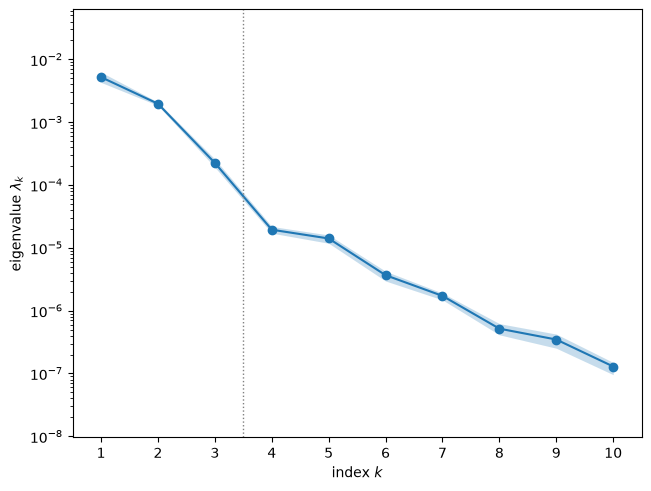

In [5]:
fig, ax = ac.plotting.plot_eigenvalues(sub3)
fig

The eigenvalues fall from $\lambda_1 = 5.214\times10^{-3}$ to $\lambda_{10} = 1.291\times10^{-7}$. The leading ratios are $\lambda_1/\lambda_2 = 2.7$, $\lambda_2/\lambda_3 = 8.7$ and $\lambda_3/\lambda_4 = 11.6$, and the first one, two and three eigenvalues hold 0.700, 0.964 and 0.995 of the sum. The rules disagree. v1's `evg` uses the linear gap, which is largest at $k = 1$ ($\lambda_1 - \lambda_2 = 3.25\times10^{-3}$ vs $1.74\times10^{-3}$), so it picks $n = 1$; but $\lambda_1/\lambda_2$ is only 2.7, and the summary plot and surrogates below show that one active variable is not enough. The ladle rule `li` and the largest ratio both pick $n = 3$, and the bootstrap separates the two candidate gaps: $\lambda_3/\lambda_4 \in [9.5, 13.7]$ against $\lambda_2/\lambda_3 \in [7.5, 10.4]$, larger in 94 % of the replicates. We therefore use $n = 3$ (the dotted line); $n = 2$ is the nearest alternative (a cubic in two active variables has a leave-one-out $R^2$ of 0.953 against 0.983 for three, see the surrogate section). On the coarse $f_0$ mesh the two gaps are nearly tied (9.69 and 9.40, below), which is why the earlier version of this notebook used $n = 2$. The bootstrap intervals of $\lambda_2$, $\lambda_3$ and $\lambda_4$ do not overlap: $\lambda_2 \in [1.849, 2.088]\times10^{-3}$, $\lambda_3 \in [1.916, 2.586]\times10^{-4}$, $\lambda_4 \in [1.713, 2.189]\times10^{-5}$.

**Subspace errors.**

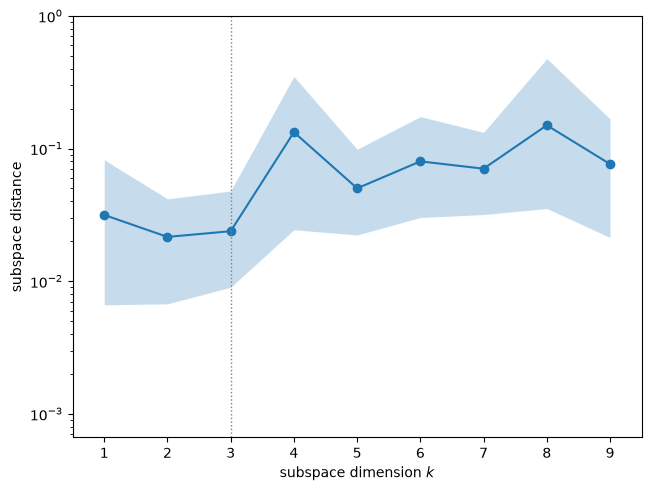

In [6]:
fig, ax = ac.plotting.plot_subspace_errors(sub3)
fig

The bootstrap mean subspace distance is 0.032 for $k = 1$, 0.022 for $k = 2$ and 0.024 for $k = 3$ (95th percentiles 0.066, 0.039, 0.042): with 500 exact gradients the sampling error of the one-, two- and three-dimensional subspaces is small. The discretization error of PyApprox's $f_0$ mesh is larger (see below); that of the order-21 mesh is far smaller.

**Eigenvectors.** The three active eigenvectors (the bootstrap subspace distances above bound their sampling error).

w1: z_1 +0.770, z_3 +0.429, z_2 +0.410; weight on z_1..z_3: 0.946
w2: z_3 +0.706, z_1 -0.584, z_6 +0.279; weight on z_1..z_3: 0.904
w3: z_2 +0.722, z_4 -0.483, z_3 -0.435; weight on z_1..z_3: 0.746


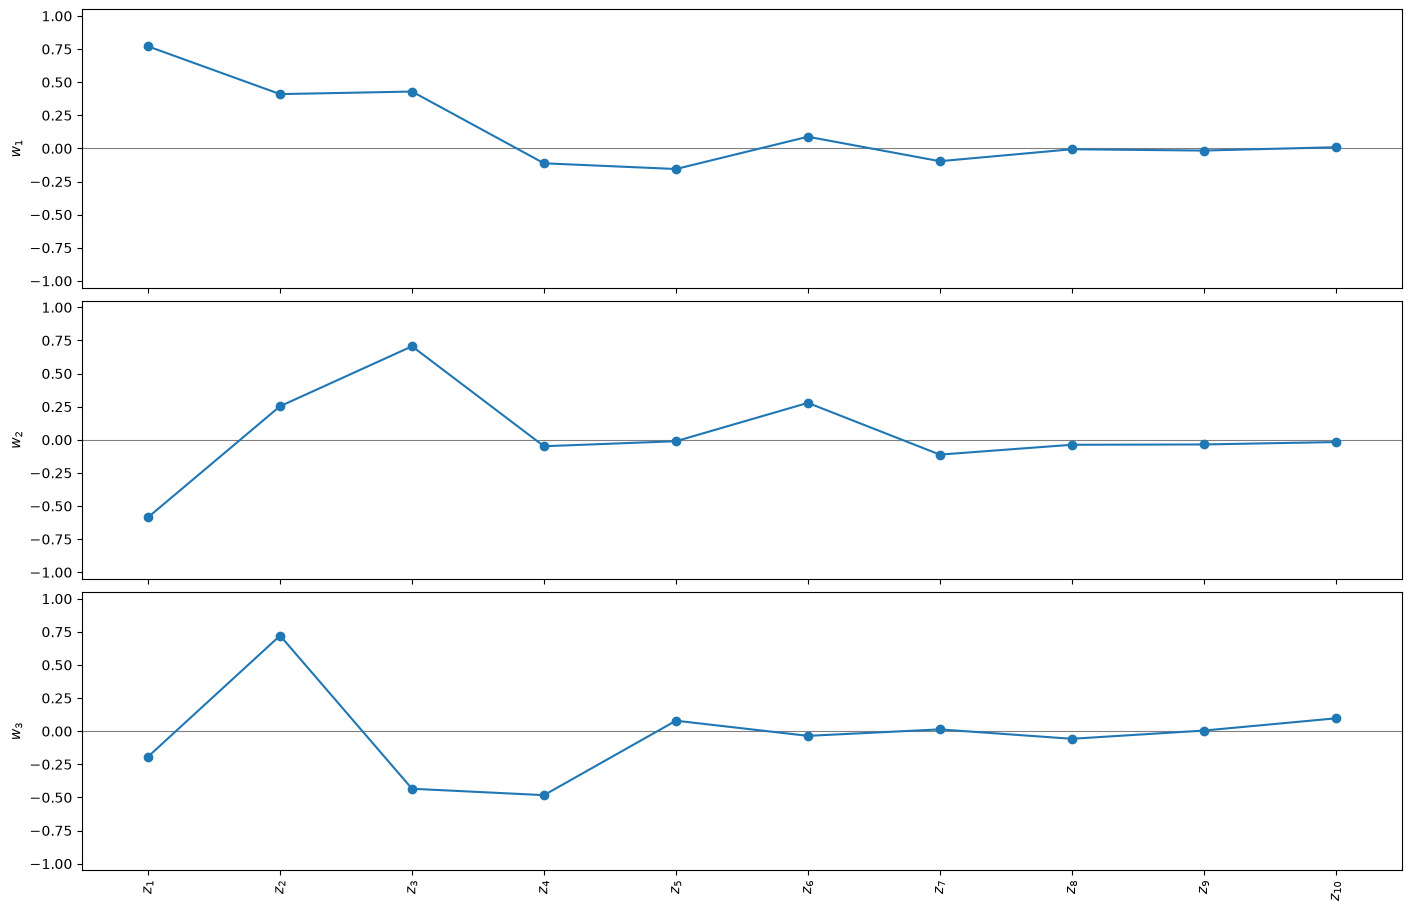

In [7]:
fig, axes = ac.plotting.plot_eigenvectors(sub3, indices=[0, 1, 2], labels=labels, figsize=(14, 9))
W = sub.W
for k in range(3):
    top = np.argsort(-np.abs(W[:, k]))[:3]
    print(f'w{k + 1}: ' + ', '.join(f'{names[j]} {W[j, k]:+.3f}' for j in top)
          + f'; weight on z_1..z_3: {np.sum(W[:3, k]**2):.3f}')
fig

The first eigenvector is made up mostly of the first three KLE coefficients ($z_1$ +0.770, $z_3$ +0.429, $z_2$ +0.410), which carry 0.946 of its squared length; the second also mostly of $z_1$–$z_3$ (0.904; $z_3$ +0.706, $z_1$ −0.584), with $z_6$ at +0.279. The third adds $z_4$ ($z_2$ +0.722, $z_4$ −0.483, $z_3$ −0.435). Importance for $q$ follows the KLE ordering by field variance only roughly. A caution: $(z_2, z_3)$, $(z_5, z_6)$, $(z_7, z_8)$ and $(z_9, z_{10})$ are equal-eigenvalue pairs, so how weight is split within a pair depends on the rotation fixed by `kle_basis.csv`; the field view below does not.

The active directions are directions in the space of log-diffusivity fields: $\mathbf w_k$ corresponds to the field $\sum_d w_{k,d}\,\phi_d(\mathbf s)$, a perturbation of $\log K$ along which $q$ changes most. We draw the three active directions, with the source (circle) and the QoI subdomain (box).

w1 field: min +0.06, max +0.98, largest |value| at s = (0.09, 0.53)
w2 field: min -0.91, max +0.18, largest |value| at s = (0.79, 0.74)
w3 field: min -0.62, max +0.62, largest |value| at s = (0.08, 1.00)


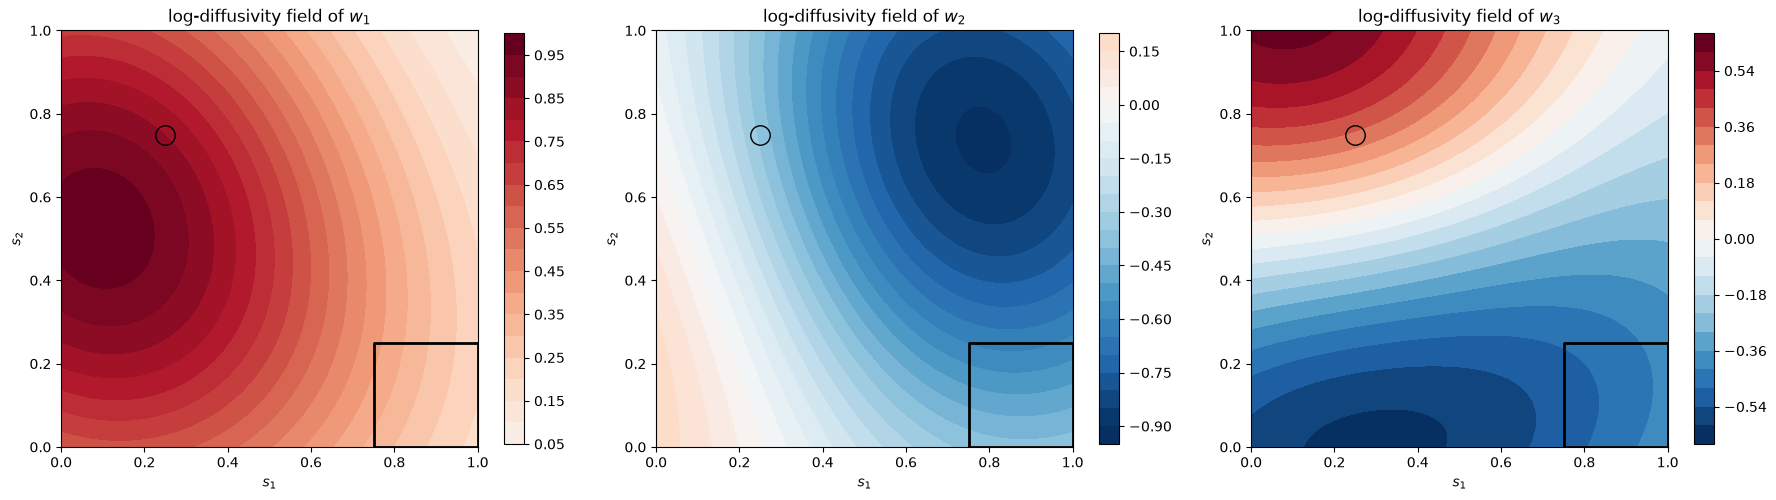

In [8]:
n1 = tm.KLE_ORDER + 1
ss = np.linspace(0, 1, 101)
Bx = tm.lagrange_matrix(tm.KLE_ORDER, 2 * ss - 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for k, ax in enumerate(axes):
    field = (phi @ W[:, k]).reshape(n1, n1)          # [i2, i1]
    F = Bx @ field @ Bx.T                            # rows s2, columns s1
    vmax = np.abs(F).max()
    cs = ax.contourf(ss, ss, F, 21, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.plot(*tm.SOURCE_LOC, 'ko', mfc='none', ms=14)
    a1, b1, a2, b2 = tm.SUBDOMAIN
    ax.plot([a1, b1, b1, a1, a1], [a2, a2, b2, b2, a2], 'k-', lw=2)
    ax.set_xlabel('$s_1$'); ax.set_ylabel('$s_2$'); ax.set_aspect('equal')
    ax.set_title(f'log-diffusivity field of $w_{k + 1}$')
    fig.colorbar(cs, ax=ax, shrink=0.85)
    i2, i1 = np.unravel_index(np.argmax(np.abs(F)), F.shape)
    print(f'w{k + 1} field: min {F.min():+.2f}, max {F.max():+.2f}, largest |value| at '
          f's = ({ss[i1]:.2f}, {ss[i2]:.2f})')
fig.tight_layout()
plt.close(fig)
fig

The field of $\mathbf w_1$ is positive everywhere (from +0.06 to +0.98), largest at $\mathbf s = (0.09, 0.53)$ near the inflow side, upstream of the source: moving along $\mathbf w_1$ raises the diffusivity almost everywhere, most of all upstream. The field of $\mathbf w_2$ ranges from −0.91, at $\mathbf s = (0.79, 0.74)$ downstream of the source, to +0.18: moving along $\mathbf w_2$ lowers the diffusivity mainly in the upper right. The field of $\mathbf w_3$ changes sign across the domain (−0.62 to +0.62, largest in magnitude at $\mathbf s = (0.08, 1.00)$, the upper-left corner).

**Sufficient summary plots.**

corr(q, w1^T z) = 0.502; q at the 10 smallest w1^T z: 0.095 to 0.305; q where w1^T z > 0: 0.437 to 0.669
mean q in the deciles of w1^T z: 0.357, 0.486, 0.514, 0.520, 0.535, 0.540, 0.542, 0.533, 0.520, 0.511; peak in decile 7


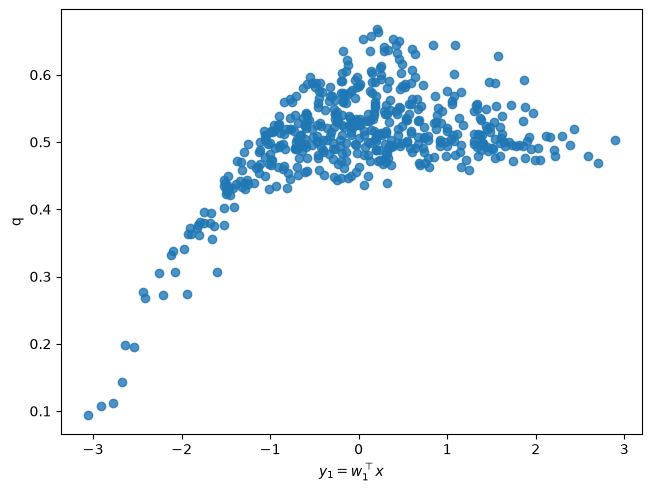

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='q')
y = X @ sub.W[:, :3]
i10 = np.argsort(y[:, 0])[:10]
dec = np.quantile(y[:, 0], np.linspace(0, 1, 11))
bins = np.digitize(y[:, 0], dec[1:-1])
means = [f[bins == b].mean() for b in range(10)]
print(f'corr(q, w1^T z) = {np.corrcoef(y[:, 0], f)[0, 1]:.3f}; q at the 10 smallest w1^T z: '
      f'{f[i10].min():.3f} to {f[i10].max():.3f}; q where w1^T z > 0: '
      f'{f[y[:, 0] > 0].min():.3f} to {f[y[:, 0] > 0].max():.3f}')
print('mean q in the deciles of w1^T z: ' + ', '.join(f'{v:.3f}' for v in means)
      + f'; peak in decile {np.argmax(means) + 1}')
fig

corr(q, w2^T z) = 0.489; corr(q, w3^T z) = 0.093


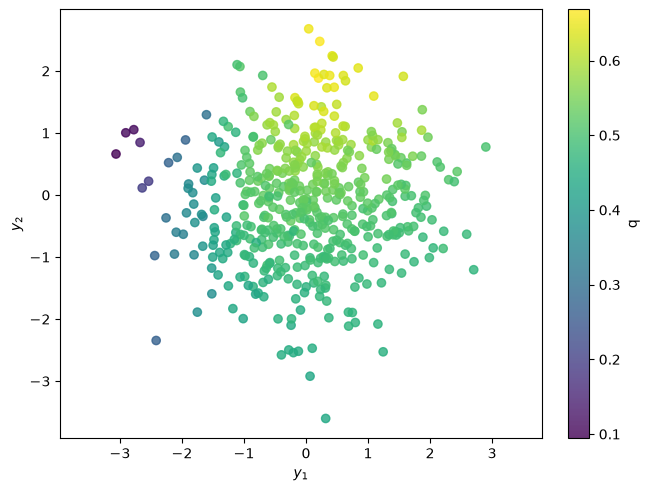

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub2, X=X, f=f, dims=2, qoi_label='q')
print(f'corr(q, w2^T z) = {np.corrcoef(y[:, 1], f)[0, 1]:.3f}; corr(q, w3^T z) = {np.corrcoef(y[:, 2], f)[0, 1]:.3f}')
fig

The one-dimensional summary plot is not a ridge along a single direction: $q$ rises steeply with $\mathbf w_1^T\mathbf z$ on the left ($q$ from 0.095 to 0.305 at the 10 smallest values), and for $\mathbf w_1^T\mathbf z > 0$ it has a wide spread (0.437 to 0.669). The mean of $q$ in the deciles of $\mathbf w_1^T\mathbf z$ rises from 0.357 to a peak of 0.542 in the seventh decile and then falls slightly, to 0.511 in the tenth; because the trend rises, peaks and falls slightly, the correlation of $q$ with $\mathbf w_1^T\mathbf z$ is only 0.502. In the two-dimensional plot the colour changes smoothly across the cloud, and $q$ also increases along $\mathbf w_2$ (correlation 0.489): most of the spread in the one-dimensional plot is the second active variable. The third active variable has almost no linear correlation with $q$ (0.093), so it acts through curvature and interaction, and it cannot be shown in a summary plot; the surrogate below measures what it adds.

### What PyApprox's $f_0$ mesh does to the subspace

PyApprox's highest-fidelity mesh $f_0$ (order 11) is coarse for a source of width 0.1. We compare $q$, the gradients and the subspace from the 500 $f_0$ rows with the order-21 ones on the same inputs, using the distance $\|\mathbf W_1\mathbf W_1^T - \mathbf V_1\mathbf V_1^T\|_2$ between $k$-dimensional subspaces (and the largest principal angle, its arcsine), and check order 21 against order 27 on the first 50 rows.

In [11]:
def sdist(A, B, k):
    return np.linalg.norm(A[:, :k] @ A[:, :k].T - B[:, :k] @ B[:, :k].T, 2)

rel = np.abs(f_f0 - f) / f
relg = np.linalg.norm(G_f0 - G, axis=1) / np.linalg.norm(G, axis=1)
print(f'f0 vs order 21, 500 rows: |dq|/q median {100 * np.median(rel):.2f} %, max {100 * rel.max():.2f} %; '
      f'gradient relative error median {np.median(relg):.3f}, 90th percentile {np.percentile(relg, 90):.3f}, '
      f'max {relg.max():.3f}')
sub_f0 = ac.active_subspace(space=space, X=X, f=f_f0, grads=G_f0, estimator='as', nboot=500, rng=SEED)
lf = sub_f0.eigenvalues
print('            ' + ''.join(f'lambda_{k + 1:<6d}' for k in range(4)) + 'ratios k = 1, 2, 3')
for lab, l in (('order 21', lam_as), ('f0', lf)):
    print(f'{lab:12s}' + ''.join(f'{v:<13.3e}' for v in l[:4]) + ', '.join(f'{l[k] / l[k + 1]:.2f}' for k in range(3)))
print(f'f0: evg n = {ac.dimension_criterion(sub_f0, rule="evg")[2]}, li n = {ac.dimension_criterion(sub_f0, rule="li")[2]}; '
      'cubic LOO R^2 in f0\'s own 1, 2, 3 active variables (f0 data): '
      + ', '.join(f'{ac.fit_surrogate(X=X, f=f_f0, space=space, subspace=ac.with_dimension(sub_f0, n), kind="poly", degree=3).loo_r_squared:.3f}' for n in (1, 2, 3)))
for k in (1, 2, 3):
    dk = sdist(sub_f0.W, sub.W, k)
    print(f'k = {k}: subspace distance f0 vs order 21 = {dk:.3f} ({np.degrees(np.arcsin(min(dk, 1))):.1f} deg); '
          f'order-21 bootstrap mean {d[k - 1]:.3f}, 95th percentile {d95[k - 1]:.3f}')
r2_f0dirs = ac.fit_surrogate(X=X, f=f, space=space, subspace=ac.with_dimension(sub_f0, 2), kind='poly', degree=3).loo_r_squared
r2_own = ac.fit_surrogate(X=X, f=f, space=space, subspace=sub2, kind='poly', degree=3).loo_r_squared
print(f'order-21 q, cubic in two active variables: LOO R^2 {r2_f0dirs:.3f} with f0\'s directions, {r2_own:.3f} with its own')
n27 = len(f27)
W21_50 = np.linalg.eigh(G[:n27].T @ G[:n27])[1][:, ::-1]
W27 = np.linalg.eigh(G27.T @ G27)[1][:, ::-1]
Wf0_50 = np.linalg.eigh(G_f0[:n27].T @ G_f0[:n27])[1][:, ::-1]
print(f'order 21 vs order 27, first {n27} rows: max |dq|/q {100 * np.max(np.abs(f[:n27] - f27) / f27):.2f} %, '
      f'max gradient error {100 * np.max(np.linalg.norm(G[:n27] - G27, axis=1) / np.linalg.norm(G27, axis=1)):.2f} %; '
      'subspace distance k = 1, 2, 3: ' + ', '.join(f'{sdist(W21_50, W27, k):.3f}' for k in (1, 2, 3))
      + ' (f0 vs order 27: ' + ', '.join(f'{sdist(Wf0_50, W27, k):.3f}' for k in (1, 2, 3)) + ')')

f0 vs order 21, 500 rows: |dq|/q median 1.25 %, max 9.31 %; gradient relative error median 0.148, 90th percentile 0.285, max 0.668


            lambda_1     lambda_2     lambda_3     lambda_4     ratios k = 1, 2, 3
order 21    5.214e-03    1.967e-03    2.249e-04    1.944e-05    2.65, 8.75, 11.56
f0          5.267e-03    1.781e-03    1.839e-04    1.957e-05    2.96, 9.69, 9.40
f0: evg n = 1, li n = 2; cubic LOO R^2 in f0's own 1, 2, 3 active variables (f0 data): 0.686, 0.950, 0.981
k = 1: subspace distance f0 vs order 21 = 0.074 (4.2 deg); order-21 bootstrap mean 0.032, 95th percentile 0.066
k = 2: subspace distance f0 vs order 21 = 0.166 (9.6 deg); order-21 bootstrap mean 0.022, 95th percentile 0.039
k = 3: subspace distance f0 vs order 21 = 0.077 (4.4 deg); order-21 bootstrap mean 0.024, 95th percentile 0.042
order-21 q, cubic in two active variables: LOO R^2 0.927 with f0's directions, 0.953 with its own
order 21 vs order 27, first 50 rows: max |dq|/q 0.19 %, max gradient error 0.72 %; subspace distance k = 1, 2, 3: 0.001, 0.002, 0.003 (f0 vs order 27: 0.076, 0.178, 0.088)


On the 500 rows the benchmark mesh changes $q$ by a median of 1.25 % and at most 9.31 %, and the gradients much more: their relative error has a median of 0.148, a 90th percentile of 0.285 and a maximum of 0.668. The eigenvalues are close ($\lambda_1$: 5.267e-3 on $f_0$, 5.214e-3 on order 21; $\lambda_2$: 1.781e-3 and 1.967e-3; $\lambda_3$: 1.839e-4 and 2.249e-4), but the gap pattern differs. On $f_0$ the two candidate gaps are nearly tied ($\lambda_2/\lambda_3 = 9.69$, $\lambda_3/\lambda_4 = 9.40$), `li` picks 2, and a cubic in $f_0$'s own three active variables has a leave-one-out $R^2$ of 0.981 against 0.950 for two, so there $n = 2$ and $n = 3$ are a choice between two nearly equal gaps; on order 21 the gap after the third eigenvalue is the larger one. The one-dimensional subspaces differ by 0.074 (4.2°), about the 95th bootstrap percentile of 0.066; the two-dimensional ones by 0.166 (9.6°), more than four times the 95th percentile of 0.039; the three-dimensional ones by 0.077 (4.4°), so the mesh mostly trades part of the second direction against the third, and the three-dimensional subspace is less affected. The rotation matters for prediction: a cubic in $f_0$'s two active variables fitted to the order-21 $q$ has a leave-one-out $R^2$ of 0.927, against 0.953 in order 21's own. Order 21 is converged for this purpose: on the first 50 rows it differs from order 27 by at most 0.19 % in $q$ and 0.72 % in the gradient, and its one-, two- and three-dimensional subspaces by 0.001, 0.002 and 0.003 (those of $f_0$ by 0.076, 0.178 and 0.088). Use `outputs_f0.csv` and `gradients_f0.csv` only when the bit-for-bit link to PyApprox's benchmark matters.

### A surrogate on the active variables

A cubic polynomial in the first one, two and three active variables (degree fixed before fitting), fitted to all 500 order-21 samples; the leave-one-out $R^2$ measures how much of $q$ the active variables explain.

1 active variable(s), degree 3: LOO R^2 = 0.665
2 active variable(s), degree 3: LOO R^2 = 0.953
3 active variable(s), degree 3: LOO R^2 = 0.983


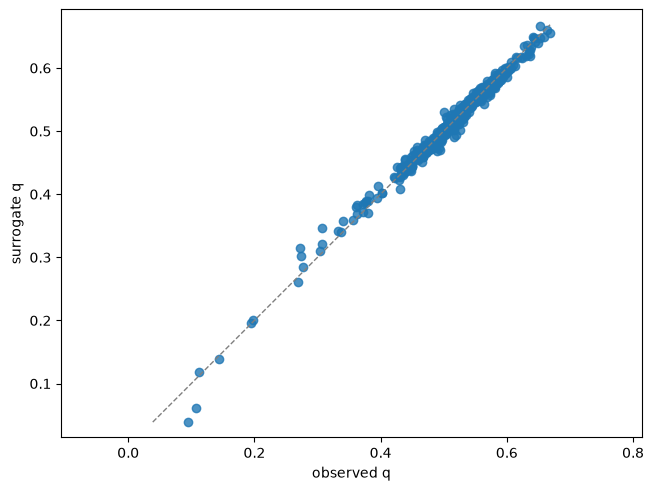

In [12]:
surr = {}
for n_act in (1, 2, 3):
    surr[n_act] = ac.fit_surrogate(X=X, f=f, space=space, subspace=ac.with_dimension(sub, n_act),
                                   kind='poly', degree=3)
    print(f'{n_act} active variable(s), degree 3: LOO R^2 = {surr[n_act].loo_r_squared:.3f}')
fig, ax = ac.plotting.plot_surrogate_fit(surr[N_ACT], X=X, f=f, qoi_label='q')
fig

A cubic in one active variable has a leave-one-out $R^2$ of 0.665, in two 0.953 and in three 0.983 (the plot shows the three-variable fit): the second active variable is essential, and the third adds a further 0.030, in line with the eigenvalue ratios and the choice $n = 3$.

### Comparison with the paper

The paper uses this model for multi-fidelity estimation (Sec. 3.5.6, Fig. 6) and does not compute an active subspace or any statistic of $q$ that we can compare directly; the table lists the settings and what the notebook reports for each.

In [13]:
rows = [
    ('KLE terms m', '3 (Sec. 3, p. 8)', '10 (user choice)'),
    ('kernel, length scale, sigma', 'squared exponential, 0.5, 1', 'same (PyApprox 1.0.3 MeshKLE, no Nystrom weights)'),
    ('final time T', '0.2 (Sec. 3.5.6)', f'{tm.FINAL_TIME}'),
    ('QoI', 'space-time integral over [3/4,1]x[0,1/4] (text)', 'space integral at t = T (code)'),
    ('distribution of z', 'posterior from Sec. 3.3 (ACV pilot)', 'prior N(0, I)'),
    ('mesh', 'f0: order 11, 64 steps (code)', f'order 21, 64 steps (+ f0 variant, order 27 check)'),
    ('high-fidelity samples', '20 (ACV pilot)', f'{len(f)} on order 21 (+ {len(f_f0)} on f0, {len(f27)} on order 27)'),
    ('q at z = 0', 'not reported', f'{model.qoi(np.zeros(10)):.6f} (order 21); {model_f0.qoi(np.zeros(10)):.6f} (f0; PyApprox 1.0.3: 0.537336)'),
    ('active subspace', 'not reported', f'n = {N_ACT} (evg {n_evg}, li {n_li}), ratios ' + ', '.join(f'{r:.1f}' for r in ratios[:3])),
]
w = [max(len(r[i]) for r in rows + [('quantity', 'paper', 'notebook')]) for i in range(3)]
for r in [('quantity', 'paper', 'notebook')] + rows:
    print('  '.join(c.ljust(w[i]) for i, c in enumerate(r)))
print(f'\nnotebook run time: {time.perf_counter() - t_start:.0f} s')

quantity                     paper                                            notebook                                                    
KLE terms m                  3 (Sec. 3, p. 8)                                 10 (user choice)                                            
kernel, length scale, sigma  squared exponential, 0.5, 1                      same (PyApprox 1.0.3 MeshKLE, no Nystrom weights)           
final time T                 0.2 (Sec. 3.5.6)                                 0.2                                                         
QoI                          space-time integral over [3/4,1]x[0,1/4] (text)  space integral at t = T (code)                              
distribution of z            posterior from Sec. 3.3 (ACV pilot)              prior N(0, I)                                               
mesh                         f0: order 11, 64 steps (code)                    order 21, 64 steps (+ f0 variant, order 27 check)           
high-fidelity samples      

The settings match the paper's where it states them, except the number of KLE terms (our choice), the QoI (we follow the code; see "Where code and paper differ"), the mesh (converged order 21 instead of the benchmark's $f_0$, which is kept as a variant) and the input distribution (prior, not posterior). The paper reports no active subspace and no statistic of $q$, so the only number we can compare is with PyApprox 1.0.3 itself: $q(\mathbf 0)$ on $f_0$ agrees to the printed digits (to $10^{-12}$ relative, `DATA.md`). The paper's finding that the best ACV estimator pairs $f_0$ with $f_4$ (finest mesh, coarsest time step; Sec. 3.5.6) fits the discretization study in `DATA.md`: the time step changes $q$ by at most 0.05 %, the mesh ($f_0$ against order 21) by a median of 1.25 % and up to 9.31 %.

### References

[1] J. D. Jakeman, PyApprox: A software package for sensitivity analysis, Bayesian inference, optimal experimental design, and multi-fidelity uncertainty quantification and surrogate modeling, *Environmental Modelling & Software* 170:105825, 2023. [doi:10.1016/j.envsoft.2023.105825](https://doi.org/10.1016/j.envsoft.2023.105825). (Volume and article number checked with Crossref; read from the accepted manuscript, SAND2023-13522J.)

[2] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

[3] L. N. Trefethen, *Spectral Methods in MATLAB*, SIAM, 2000. [doi:10.1137/1.9780898719598](https://doi.org/10.1137/1.9780898719598). (Chebyshev collocation and differentiation matrices.)

### Acknowledgments

The paper states that the development of PyApprox was sponsored by the Sandia National Laboratories Laboratory Directed Research and Development (LDRD) program, the US Department of Energy's Office of Advanced Scientific Computing Research, Office of Biological and Environmental Research, and Scientific Discovery through Advanced Computing (SciDAC) program, and the Defense Advanced Research Projects Agency (DARPA). Sandia National Laboratories is managed and operated by NTESS for the U.S. Department of Energy's National Nuclear Security Administration under contract DE-NA0003525.